In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Update this path if your CSV is stored in another folder.
df = pd.read_csv("../DataCo_Cleaned_Interim.csv")

print("Raw rows:", len(df))
print("Distinct Order IDs:", df["Order Id"].nunique())
print("Regions:", df["Order Region"].nunique())

Raw rows: 180519
Distinct Order IDs: 65752
Regions: 23


In [ ]:
orders = df.groupby("Order Id", as_index=False).agg(
    region=("Order Region", "first"),
    order_status=("Order Status", "first"),
    delivery_status=("Delivery Status", "first"),
)
orders["region"] = orders["region"].fillna("Unknown")

delivery_eligible_labels = [
    "Advance shipping", "Shipping on time", "Late delivery"
]
on_time_labels = ["Advance shipping", "Shipping on time"]

regional = orders.groupby("region").apply(
    lambda g: pd.Series({
        "Total Distinct Orders": g["Order Id"].nunique(),
        "Eligible Delivered Orders": g["delivery_status"].isin(delivery_eligible_labels).sum(),
        "On-Time/Advance Orders": g["delivery_status"].isin(on_time_labels).sum(),
        "Cancelled Orders": (g["order_status"] == "CANCELED").sum(),
    }),
    include_groups=False
).reset_index().rename(columns={"region": "Region"})

regional["On-Time Delivery Rate (%)"] = (
    regional["On-Time/Advance Orders"] /
    regional["Eligible Delivered Orders"].replace(0, pd.NA) * 100
).fillna(0)

regional["Cancellation Rate (%)"] = (
    regional["Cancelled Orders"] /
    regional["Total Distinct Orders"].replace(0, pd.NA) * 100
).fillna(0)

regional = regional.sort_values("Total Distinct Orders", ascending=False)
regional.round(2)

,Region,Total Distinct Orders,Eligible Delivered Orders,On-Time/Advance Orders,Cancelled Orders,On-Time Delivery Rate (%),Cancellation Rate (%)
22,Western Europe,10010,9563,3978,197,41.60,1.97
3,Central America,9396,9001,3845,184,42.72,1.96
12,South America,4979,4738,2042,122,43.10,2.45
11,Oceania,4362,4175,1793,87,42.95,1.99
15,Southeast Asia,4356,4173,1752,99,41.98,2.27
10,Northern Europe,3716,3564,1568,82,44.00,2.21
17,Southern Europe,3543,3390,1495,70,44.10,1.98
13,South Asia,3335,3219,1354,57,42.06,1.71
7,Eastern Asia,3318,3171,1353,72,42.67,2.17
1,Caribbean,2806,2675,1188,63,44.41,2.25


In [ ]:
print("Sum of regional order counts:", regional["Total Distinct Orders"].sum())
print("Distinct orders in dataset:", orders["Order Id"].nunique())
print("Sum of regional cancellations:", regional["Cancelled Orders"].sum())
assert regional["Total Distinct Orders"].sum() == orders["Order Id"].nunique()
assert (regional["On-Time/Advance Orders"] <= regional["Eligible Delivered Orders"]).all()
assert (regional["Cancelled Orders"] <= regional["Total Distinct Orders"]).all()
print("Validation checks passed.")

Sum of regional order counts: 65752
Distinct orders in dataset: 65752
Sum of regional cancellations: 1367
Validation checks passed.


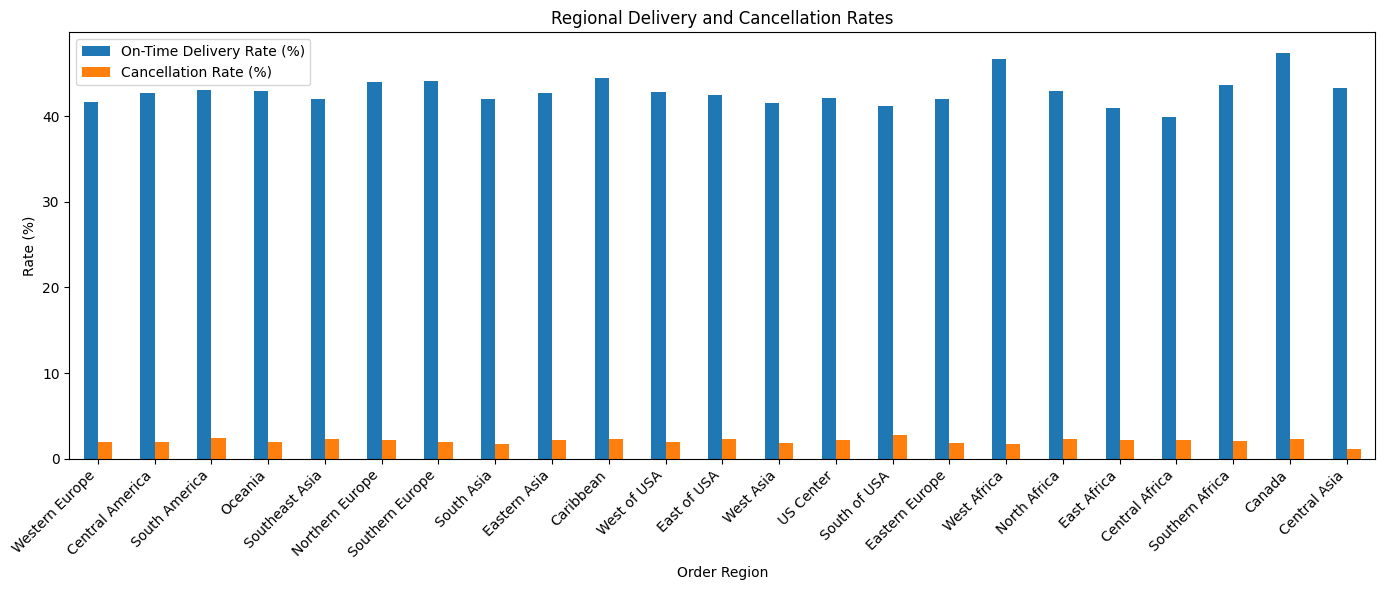

In [8]:
regional.set_index("Region")[[
    "On-Time Delivery Rate (%)", "Cancellation Rate (%)"
]].plot(kind="bar", figsize=(14, 6))
plt.title("Regional Delivery and Cancellation Rates")
plt.ylabel("Rate (%)")
plt.xlabel("Order Region")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
regional.to_excel("10_Regional_Performance_Summary.xlsx", index=False)
regional.to_csv("10_Regional_Performance_Summary.csv", index=False)
print("Regional summary exported.")

Regional summary exported.
